# What do playoff teams draft?

Every 12-team PPR **redraft** league in the crawl (2020–2025), one row per team: how it drafted
and whether it made the playoffs. This is the same historical signal the draft room's
recommendations are built on, looked at directly.

Outcome = `rosters.made_playoffs`. The baseline is the share of all teams that got in (set by
league playoff size), so every result below is read as a **lift over baseline**. All numbers are
observational: they show what playoff teams did, not proof that the strategy caused it (draft
slot, manager skill and in-season moves all mix in).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import query, style, binom_ci, POS_COLORS, INK, INK_3, STAMP

style()
pd.set_option("display.precision", 3)

In [2]:
teams = query("""
    SELECT p.league_id, p.owner_id, l.league_type, l.season,
           MIN(CASE WHEN p.round = 1 THEN p.draft_slot END) AS slot,
           GROUP_CONCAT(CASE WHEN p.round <= 3 THEN p.position END ORDER BY p.round SEPARATOR '-') AS start,
           SUM(p.round <= 5 AND p.position = 'RB') AS rb_top5,
           SUM(p.round <= 5 AND p.position = 'WR') AS wr_top5,
           MIN(CASE WHEN p.position = 'QB' THEN p.round END) AS first_qb,
           MIN(CASE WHEN p.position = 'TE' THEN p.round END) AS first_te
    FROM draft_picks p JOIN leagues l ON l.league_id = p.league_id
    WHERE l.league_format = 'redraft' AND l.league_size = 12 AND l.scoring_type = '1.0'
    GROUP BY p.league_id, p.owner_id, l.league_type, l.season
""", cache="redraft12_ppr_teams")
outcomes = query("""
    SELECT r.league_id, r.owner_id, r.made_playoffs, r.wins, r.losses
    FROM rosters r JOIN leagues l ON l.league_id = r.league_id
    WHERE l.league_format = 'redraft' AND l.league_size = 12 AND l.scoring_type = '1.0'
""", cache="redraft12_ppr_outcomes")

df = teams.merge(outcomes, on=["league_id", "owner_id"])
df["fmt"] = df.league_type.map({"standard": "1QB", "qb_premium": "Superflex"})
df = df[df.start.str.count("-") == 2].dropna(subset=["slot"])   # teams with 3 real early picks
df["slot"] = df.slot.astype(int)
print(f"{len(df):,} teams in {df.league_id.nunique():,} leagues")
df.groupby("fmt").agg(teams=("made_playoffs", "size"), playoff_rate=("made_playoffs", "mean"))

118,323 teams in 10,612 leagues


,teams,playoff_rate
fmt,,
1QB,86686,0.440
Superflex,31637,0.437


## 1. Opening three picks

Playoff rate by the positions taken in rounds 1–3, for patterns with at least 500 teams. Bars
are colored by the first pick's position; error bars are 95% intervals; the dashed line is the
baseline for that format.

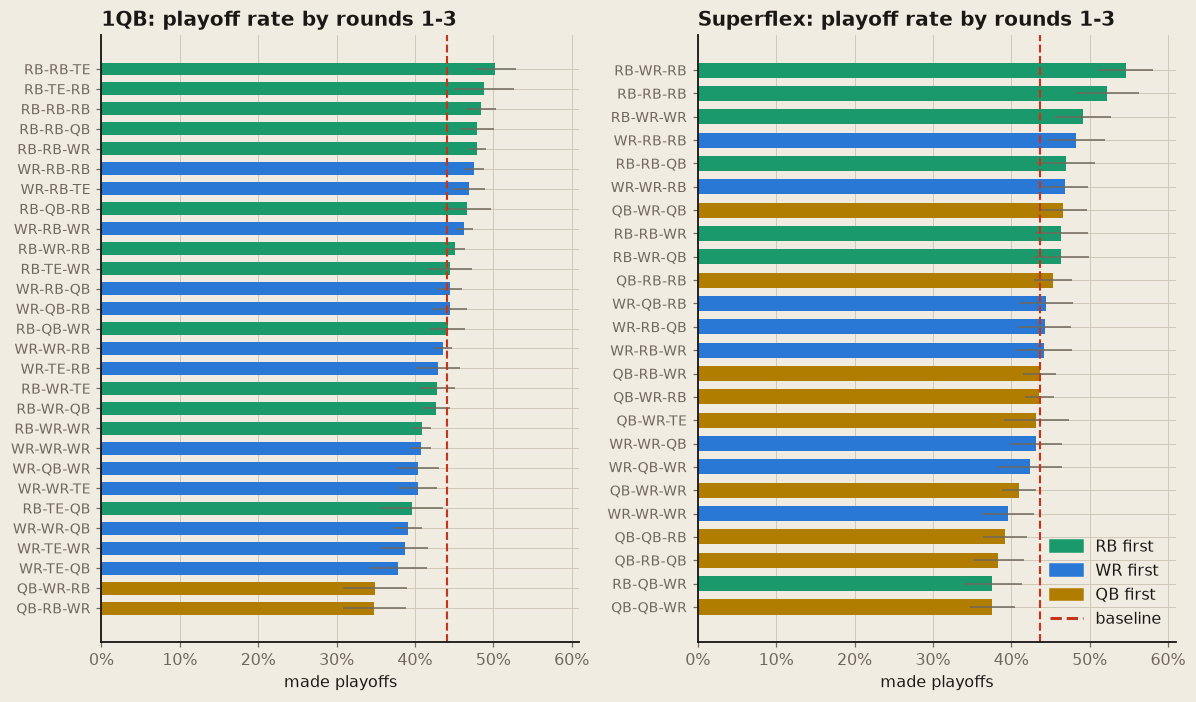

In [3]:
def start_table(sub, min_n=500):
    base = sub.made_playoffs.mean()
    t = (sub.groupby("start").made_playoffs.agg(["size", "mean"])
         .rename(columns={"size": "teams", "mean": "playoff_rate"}).query("teams >= @min_n"))
    t["lift"] = t.playoff_rate - base
    t["ci"] = binom_ci(t.playoff_rate, t.teams)
    return t.sort_values("playoff_rate"), base

fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), sharex=True)
for ax, fmt in zip(axes, ["1QB", "Superflex"]):
    t, base = start_table(df[df.fmt == fmt])
    first = [s.split("-")[0] for s in t.index]
    ax.barh(t.index, t.playoff_rate, xerr=t.ci, color=[POS_COLORS[f] for f in first],
            height=0.65, error_kw={"ecolor": INK_3, "elinewidth": 1})
    ax.axvline(base, color=STAMP, ls="--", lw=1.4)
    ax.set_title(f"{fmt}: playoff rate by rounds 1-3")
    ax.set_xlabel("made playoffs")
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.tick_params(axis="y", labelsize=9)
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color=POS_COLORS[p], label=f"{p} first") for p in ["RB", "WR", "QB"]]
               + [plt.Line2D([], [], color=STAMP, ls="--", label="baseline")], loc="lower right")
fig.tight_layout()

In [4]:
t1, base1 = start_table(df[df.fmt == "1QB"])
t1.sort_values("lift", ascending=False).head(8).style.format(
    {"playoff_rate": "{:.1%}", "lift": "{:+.1%}", "ci": "±{:.1%}", "teams": "{:,}"})

,teams,playoff_rate,lift,ci
start,,,,
RB-RB-TE,"1,367",50.3%,+6.2%,±2.7%
RB-TE-RB,657,48.9%,+4.8%,±3.8%
RB-RB-RB,"2,730",48.4%,+4.4%,±1.9%
RB-RB-QB,"2,055",48.0%,+3.9%,±2.2%
RB-RB-WR,"7,739",48.0%,+3.9%,±1.1%
WR-RB-RB,"6,118",47.6%,+3.5%,±1.3%
WR-RB-TE,"2,171",46.8%,+2.8%,±2.1%
RB-QB-RB,997,46.6%,+2.6%,±3.1%


## 2. How many RBs by round 5

RB scarcity is the core idea behind RB-heavy starts. Playoff rate by the number of RBs taken in
rounds 1–5.

fmt,1QB,Superflex
rb_top5,,
0.0,0.382,0.411
1.0,0.420,0.428
2.0,0.448,0.446
3.0,0.472,0.473
4.0,0.461,0.493


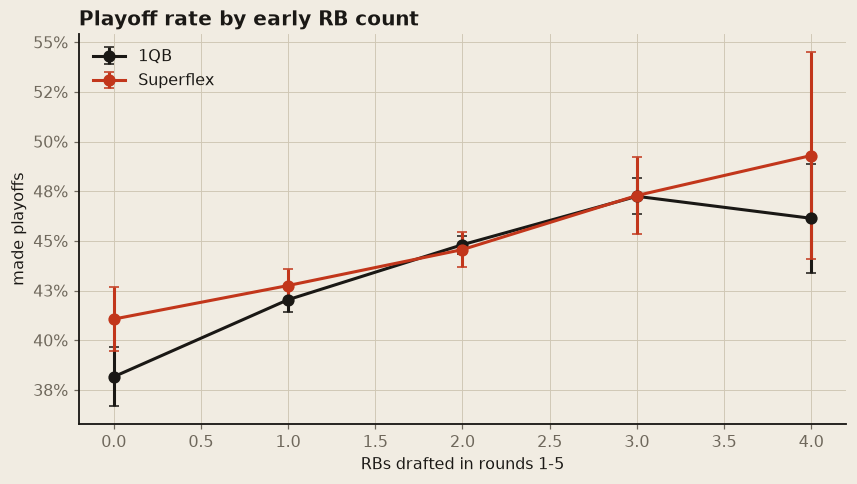

In [5]:
rb = (df.groupby(["fmt", "rb_top5"]).made_playoffs.agg(["size", "mean"]).reset_index()
      .query("size >= 300"))
fig, ax = plt.subplots()
for fmt, color in [("1QB", INK), ("Superflex", STAMP)]:
    r = rb[rb.fmt == fmt]
    ax.errorbar(r.rb_top5, r["mean"], yerr=binom_ci(r["mean"], r["size"]), marker="o",
                ms=7, capsize=3, color=color, label=fmt)
ax.set_xlabel("RBs drafted in rounds 1-5")
ax.set_ylabel("made playoffs")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Playoff rate by early RB count")
ax.legend()
rb.pivot(index="rb_top5", columns="fmt", values="mean")

## 3. When to take the first QB

The one place 1QB and superflex should disagree: in superflex a QB can start in two slots, so
waiting should cost more.

fmt,1QB,Superflex
first_qb,,
1,0.325,0.424
2,0.434,0.403
3,0.429,0.447
4,0.425,0.464
5,0.435,0.500
6,0.434,0.466
7,0.453,0.437
8,0.449,0.443
9,0.465,NaN


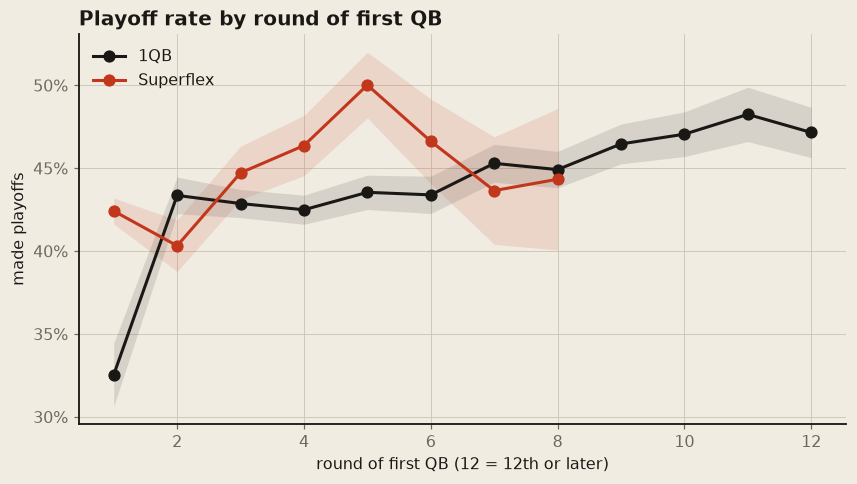

In [6]:
qb = df.dropna(subset=["first_qb"]).copy()
qb["first_qb"] = qb.first_qb.clip(upper=12).astype(int)
q = qb.groupby(["fmt", "first_qb"]).made_playoffs.agg(["size", "mean"]).reset_index().query("size >= 300")
fig, ax = plt.subplots()
for fmt, color in [("1QB", INK), ("Superflex", STAMP)]:
    r = q[q.fmt == fmt]
    ax.plot(r.first_qb, r["mean"], marker="o", ms=7, color=color, label=fmt)
    ax.fill_between(r.first_qb, r["mean"] - binom_ci(r["mean"], r["size"]),
                    r["mean"] + binom_ci(r["mean"], r["size"]), color=color, alpha=0.12, lw=0)
ax.set_xlabel("round of first QB (12 = 12th or later)")
ax.set_ylabel("made playoffs")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Playoff rate by round of first QB")
ax.legend()
q.pivot(index="first_qb", columns="fmt", values="mean")

## 4. Does draft slot matter?

If early slots won far more often, every comparison above would be confounded by who picks
first. Check it, then redo the opening-picks comparison *within* slot groups.

slot,1,2,3,4,5,6,7,8,9,10,11,12
fmt,,,,,,,,,,,,
1QB,0.388,0.466,0.465,0.470,0.467,0.434,0.446,0.440,0.432,0.424,0.430,0.424
Superflex,0.424,0.440,0.420,0.432,0.442,0.419,0.450,0.456,0.427,0.448,0.442,0.445


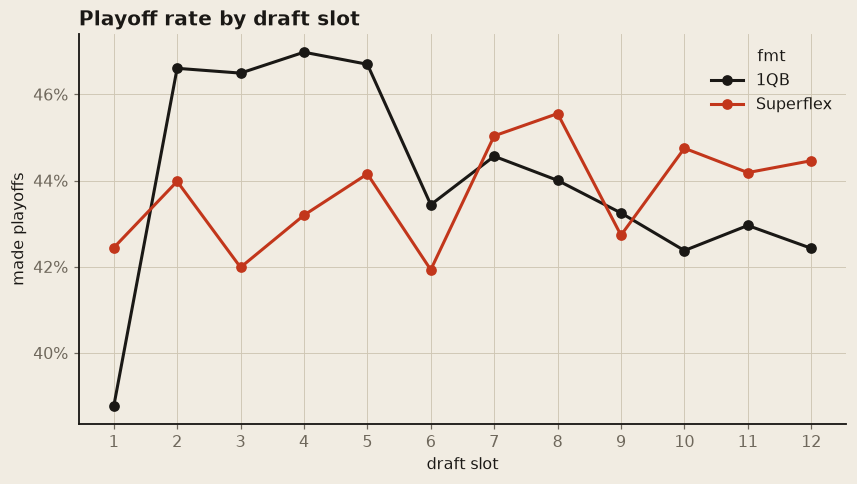

In [7]:
s = df.groupby(["fmt", "slot"]).made_playoffs.mean().unstack(0)
ax = s.plot(marker="o", color=[INK, STAMP])
ax.set_xticks(range(1, 13))
ax.set_xlabel("draft slot")
ax.set_ylabel("made playoffs")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Playoff rate by draft slot")
s.T

In [8]:
# Lift measured inside each slot group (early 1-4, middle 5-8, late 9-12) and then averaged,
# so draft position can't explain it.
one = df[df.fmt == "1QB"].copy()
one["slot_group"] = pd.cut(one.slot, [0, 4, 8, 12], labels=["early", "middle", "late"])
one["lift"] = one.made_playoffs - one.groupby("slot_group", observed=True).made_playoffs.transform("mean")
by_slot = (one.groupby(["start", "slot_group"], observed=True).lift.agg(["mean", "size"])
           .query("size >= 150").reset_index())
wide = by_slot.pivot(index="start", columns="slot_group", values="mean").dropna()
wide["avg"] = wide.mean(axis=1)
wide.sort_values("avg", ascending=False).style.format("{:+.1%}")

slot_group,early,middle,late,avg
start,,,,
RB-RB-TE,+7.3%,+6.4%,+3.9%,+5.9%
RB-RB-RB,+6.6%,+2.8%,+2.9%,+4.1%
RB-RB-WR,+5.1%,+4.0%,+2.7%,+3.9%
RB-RB-QB,+9.5%,+2.8%,-0.9%,+3.8%
WR-RB-RB,+4.8%,+2.9%,+2.9%,+3.5%
WR-RB-TE,-0.8%,+4.4%,+4.4%,+2.6%
WR-RB-WR,-0.9%,+4.0%,+3.2%,+2.1%
RB-WR-RB,+1.3%,+1.0%,+1.1%,+1.1%
RB-QB-RB,+7.0%,+1.8%,-6.8%,+0.7%


## 5. Is it stable year to year?

A real edge should show up every season, not just one. RB-RB openings (any third pick) versus
everyone else, by season.

rb_rb,other,RB-RB,lift,teams
season,,,,
2020,0.511,0.533,0.022,426
2021,0.434,0.453,0.018,1369
2022,0.476,0.381,-0.095,5156
2023,0.454,0.420,-0.034,21947
2024,0.440,0.465,0.026,21316
2025,0.408,0.539,0.131,36472


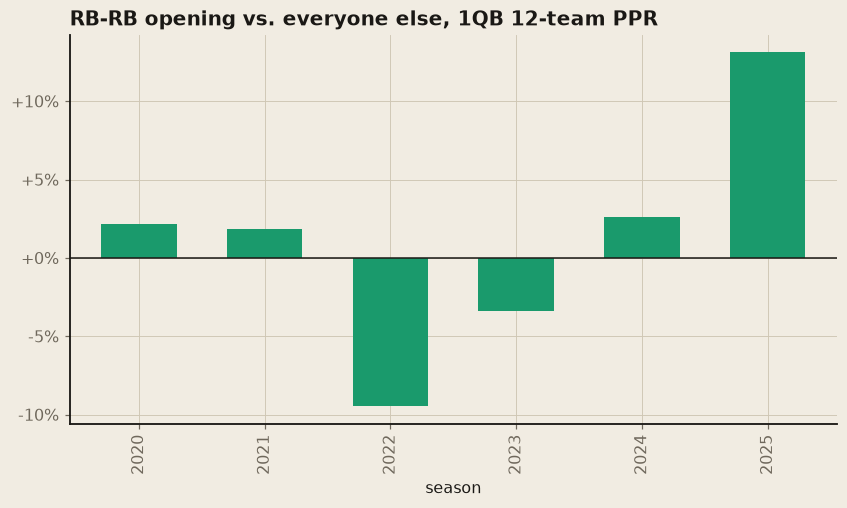

In [9]:
one["rb_rb"] = one.start.str.startswith("RB-RB")
yr = one.groupby(["season", "rb_rb"]).made_playoffs.mean().unstack()
yr["lift"] = yr[True] - yr[False]
yr["teams"] = one.groupby("season").size()
ax = yr.lift.plot(kind="bar", color=POS_COLORS["RB"], width=0.6)
ax.axhline(0, color=INK, lw=1)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:+.0%}")
ax.set_xlabel("season")
ax.set_title("RB-RB opening vs. everyone else, 1QB 12-team PPR")
yr.rename(columns={True: "RB-RB", False: "other"})

## Takeaways

Based on 86,840 1QB teams and 31,880 superflex teams. Baseline playoff rate is about 44% in both.

- **Two RBs to open wins.** In 1QB leagues every opening that starts RB-RB beats the baseline:
  RB-RB-TE got in 50.2% of the time (+6.1 points) and RB-RB-WR 47.9% (+3.9). WR-WR-WR was
  about 41%. The edge holds inside early, middle and late draft slots, so draft position doesn't
  explain it.
- **Early RB count is a steady ramp.** In 1QB leagues, 0 RBs by round 5 made the playoffs 38.1%
  of the time, and 3 RBs made it 47.3%.
- **QB timing flips between formats.** In 1QB leagues a round-1 QB was the worst choice in the
  data (32.5%), and playoff rate rises the longer a team waits (about 48% for a QB in rounds
  9-11). In superflex the best time was round 5 (49.8%). A round-1 or round-2 QB still
  underperformed there.
- **Slot 1 is the weakest slot** (38.8% in 1QB vs. about 46-47% for slots 2-5). The long wait
  until pick 24 seems to cost more than the top pick is worth.
- **Caveat: the RB edge swings by season.** RB-RB vs. everyone else ranged from -9.4 points
  (2022) to +13.1 (2025). The crawl has far more 2023-2025 leagues, so the pooled averages lean
  on recent seasons. These are good priors, not fixed rules, which is why the draft room
  matches against drafts that look like yours instead of applying one formula.